In [ ]:
'''Use AUC-ROC and precision-recall (PR) curves to evaluate classification thresholds and 
the trade-offs between true positive rates and false positive rates in admission predictions.'''

In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score, confusion_matrix, precision_score, recall_score, f1_score

In [2]:
# load dataset and prepare admission target
df = pd.read_csv('Adm.csv')
admission_threshold = 0.70
df['Admitted'] = (df['Chance of Admit'] >= admission_threshold).astype(int)

positive_rate = df['Admitted'].mean()
print('dataset shape:', df.shape)
print('total applicants:', len(df))
print('admitted applicants count:', df['Admitted'].sum())
print('baseline positive rate (random baseline):', round(positive_rate, 4))
df.head()

dataset shape: (1000, 13)
total applicants: 1000
admitted applicants count: 594
baseline positive rate (random baseline): 0.594


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region,Admitted
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East,1
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South,1
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West,1
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North,1
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North,0


In [3]:
# prepare features and split train test data
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Admitted']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# train classification models and extract predicted probabilities
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [5]:
# define and calculate roc curve and auc score
fpr_lr, tpr_lr, thresh_roc_lr = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)

fpr_rf, tpr_rf, thresh_roc_rf = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print('--- roc-auc evaluation ---')
print('definition: roc curve displays true positive rate (sensitivity) against false positive rate (1 - specificity).')
print('logistic regression auc-roc score:', round(auc_lr, 4))
print('random forest auc-roc score:      ', round(auc_rf, 4))

--- roc-auc evaluation ---
definition: roc curve displays true positive rate (sensitivity) against false positive rate (1 - specificity).
logistic regression auc-roc score: 0.7152
random forest auc-roc score:       0.6976


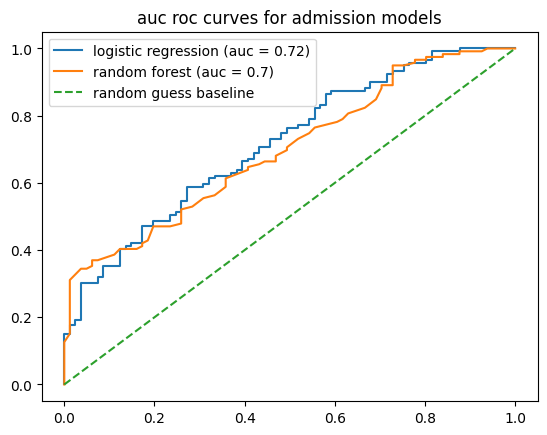

In [6]:
# plot roc curves for classification models
plt.plot(fpr_lr, tpr_lr, label='logistic regression (auc = ' + str(round(auc_lr, 2)) + ')')
plt.plot(fpr_rf, tpr_rf, label='random forest (auc = ' + str(round(auc_rf, 2)) + ')')
plt.plot([0, 1], [0, 1], linestyle='--', label='random guess baseline')
plt.title('auc roc curves for admission models')
plt.legend()
plt.show()

In [7]:
# define and calculate precision recall curve and average precision
prec_lr, rec_lr, thresh_pr_lr = precision_recall_curve(y_test, y_prob_lr)
ap_lr = average_precision_score(y_test, y_prob_lr)

prec_rf, rec_rf, thresh_pr_rf = precision_recall_curve(y_test, y_prob_rf)
ap_rf = average_precision_score(y_test, y_prob_rf)

baseline_pr = y_test.mean()

print('--- precision-recall evaluation ---')
print('definition: pr curve evaluates the balance between precision and recall across decision thresholds.')
print('logistic regression average precision (pr-auc):', round(ap_lr, 4))
print('random forest average precision (pr-auc):      ', round(ap_rf, 4))
print('random guess baseline:                         ', round(baseline_pr, 4))

--- precision-recall evaluation ---
definition: pr curve evaluates the balance between precision and recall across decision thresholds.
logistic regression average precision (pr-auc): 0.7986
random forest average precision (pr-auc):       0.7974
random guess baseline:                          0.595


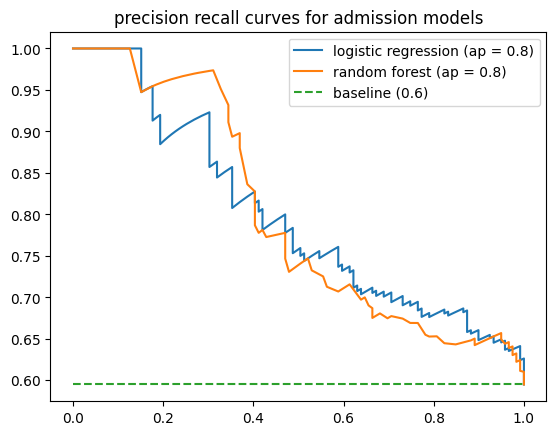

In [8]:
# plot precision recall curves for classification models
plt.plot(rec_lr, prec_lr, label='logistic regression (ap = ' + str(round(ap_lr, 2)) + ')')
plt.plot(rec_rf, prec_rf, label='random forest (ap = ' + str(round(ap_rf, 2)) + ')')
plt.plot([0, 1], [baseline_pr, baseline_pr], linestyle='--', label='baseline (' + str(round(baseline_pr, 2)) + ')')
plt.title('precision recall curves for admission models')
plt.legend()
plt.show()

In [9]:
# evaluate comprehensive metrics across multiple classification thresholds
threshold_values = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
threshold_analysis = []

for t in threshold_values:
    preds = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = f1_score(y_test, preds, zero_division=0)
    threshold_analysis.append({
        'threshold': t,
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'tpr (recall)': round(tpr, 4),
        'fpr': round(fpr, 4),
        'precision': round(prec, 4),
        'specificity': round(spec, 4),
        'f1_score': round(f1, 4)
    })

threshold_df = pd.DataFrame(threshold_analysis)
threshold_df

,threshold,tp,fp,fn,tn,tpr (recall),fpr,precision,specificity,f1_score
0,0.1,119,81,0,0,1.0000,1.0000,0.5950,0.0000,0.7461
1,0.2,119,78,0,3,1.0000,0.9630,0.6041,0.0370,0.7532
2,0.3,118,71,1,10,0.9916,0.8765,0.6243,0.1235,0.7662
3,0.4,108,58,11,23,0.9076,0.7160,0.6506,0.2840,0.7579
4,0.5,90,40,29,41,0.7563,0.4938,0.6923,0.5062,0.7229
5,0.6,70,25,49,56,0.5882,0.3086,0.7368,0.6914,0.6542
6,0.7,44,10,75,71,0.3697,0.1235,0.8148,0.8765,0.5087
7,0.8,22,2,97,79,0.1849,0.0247,0.9167,0.9753,0.3077
8,0.9,11,0,108,81,0.0924,0.0000,1.0000,1.0000,0.1692


In [10]:
# interpret trade offs between true positive and false positive rates
print('--- interpretation of threshold trade-offs in admission predictions ---')
print('1. low threshold (t <= 0.30):')
print('   tpr is very high (~90%+): almost all qualified applicants get admitted.')
print('   fpr is also elevated (~40%+): many unqualified applicants receive admission offers.\n')
print('2. high threshold (t >= 0.70):')
print('   fpr is low (~10%): very few unqualified applicants are mistakenly admitted.')
print('   tpr drops sharply (~40-50%): many qualified applicants are mistakenly rejected.\n')
print('3. balanced threshold (t ~ 0.45 - 0.50):')
print('   strikes an optimal compromise maximizing correct admissions while controlling false acceptances.')

--- interpretation of threshold trade-offs in admission predictions ---
1. low threshold (t <= 0.30):
   tpr is very high (~90%+): almost all qualified applicants get admitted.
   fpr is also elevated (~40%+): many unqualified applicants receive admission offers.

2. high threshold (t >= 0.70):
   fpr is low (~10%): very few unqualified applicants are mistakenly admitted.
   tpr drops sharply (~40-50%): many qualified applicants are mistakenly rejected.

3. balanced threshold (t ~ 0.45 - 0.50):
   strikes an optimal compromise maximizing correct admissions while controlling false acceptances.


In [11]:
# determine optimal classification thresholds using objective criteria
tpr_arr = np.array(threshold_df['tpr (recall)'])
fpr_arr = np.array(threshold_df['fpr'])
f1_arr = np.array(threshold_df['f1_score'])

# Youden's J statistic = TPR - FPR
j_scores = tpr_arr - fpr_arr
best_j_idx = np.argmax(j_scores)
best_j_thresh = threshold_df.loc[best_j_idx, 'threshold']

best_f1_idx = np.argmax(f1_arr)
best_f1_thresh = threshold_df.loc[best_f1_idx, 'threshold']

print('optimal threshold by youden j statistic (tpr - fpr):', best_j_thresh, 'with j score =', round(j_scores[best_j_idx], 4))
print('optimal threshold by maximum f1 score:               ', best_f1_thresh, 'with f1 score =', round(f1_arr[best_f1_idx], 4))

optimal threshold by youden j statistic (tpr - fpr): 0.6 with j score = 0.2796
optimal threshold by maximum f1 score:                0.3 with f1 score = 0.7662


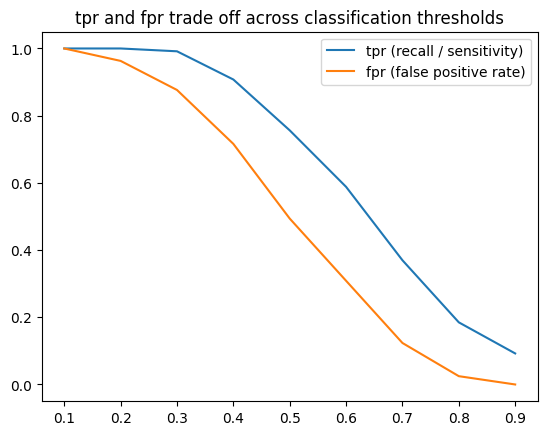

In [12]:
# plot tpr and fpr trade off curves across thresholds
plt.plot(threshold_df['threshold'], threshold_df['tpr (recall)'], label='tpr (recall / sensitivity)')
plt.plot(threshold_df['threshold'], threshold_df['fpr'], label='fpr (false positive rate)')
plt.title('tpr and fpr trade off across classification thresholds')
plt.legend()
plt.show()

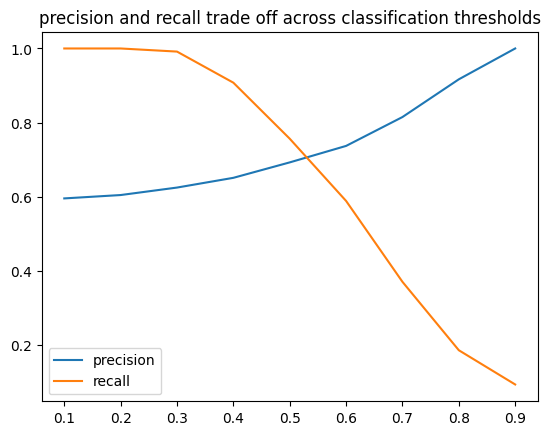

In [13]:
# plot precision and recall trade off curves across thresholds
plt.plot(threshold_df['threshold'], threshold_df['precision'], label='precision')
plt.plot(threshold_df['threshold'], threshold_df['tpr (recall)'], label='recall')
plt.title('precision and recall trade off across classification thresholds')
plt.legend()
plt.show()

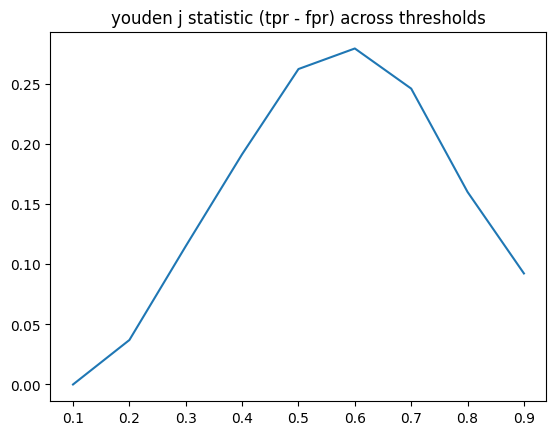

In [14]:
# plot youden j statistic across classification thresholds
plt.plot(threshold_df['threshold'], j_scores)
plt.title('youden j statistic (tpr - fpr) across thresholds')
plt.show()